# Cleaning

## Daten Laden

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv("../data/20min_metadaten_keywords.csv")

## Übersicht der Daten

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 449177 entries, 0 to 449176
Data columns (total 13 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   url                 449177 non-null  object 
 1   datum               449177 non-null  object 
 2   titel               449177 non-null  object 
 3   beschreibung        449173 non-null  object 
 4   autor               353177 non-null  object 
 5   quelle              449177 non-null  object 
 6   ressort             449177 non-null  object 
 7   likes               448300 non-null  float64
 8   kommentare          81538 non-null   float64
 9   kommentare_erlaubt  449177 non-null  bool   
 10  shares              448300 non-null  float64
 11  keywords            449177 non-null  object 
 12  clean_terms         449177 non-null  object 
dtypes: bool(1), float64(3), object(9)
memory usage: 41.6+ MB


In [4]:
data.describe()

,likes,kommentare,shares
count,448300.000000,81538.000000,448300.000000
mean,259.185519,84.841792,53.032775
std,1318.444137,159.111875,312.189251
min,0.000000,0.000000,0.000000
25%,0.000000,10.000000,0.000000
50%,0.000000,30.000000,0.000000
75%,155.000000,91.000000,12.000000
max,541077.000000,9561.000000,93485.000000


In [5]:
data.head()

,url,datum,titel,beschreibung,autor,quelle,ressort,likes,kommentare,kommentare_erlaubt,shares,keywords,clean_terms
0,https://www.20min.ch/story/robert-palmer-ist-t...,2003-10-01T13:40:00.000Z,Nachruf: Robert Palmer ist tot,Der britische Popmusiker Robert Palmer ist tot...,Jonas Bucher,20 Minuten,People,0.0,NaN,False,0.0,"Palmer (0.0339), Robert (0.0582), tot (0.0630)...","Palmer, Robert, Paris, Angaben, Staatsanwaltsc..."
1,https://www.20min.ch/story/ohne-grenzgaenger-g...,2003-10-01T02:42:00.000Z,Eric Weber: «Ohne Grenzgänger gäbe es keine Ar...,Ständeratskandidat Eric Weber von der Volks-Ak...,Daniel Waldmeier,20 Minuten,Schweiz,4.0,NaN,False,0.0,"Weber (0.0358), Ständeratskandidat (0.0670), A...","Weber, Eric, Grenzgänger, Schweiz, Basel, Arbe..."
2,https://www.20min.ch/story/der-drache-hat-ausg...,2003-10-20T02:06:00.000Z,Drachenboot Thunersee: Der Drache hat ausgefaucht,Abschiedsfahrt des Drachenschiffs.,Jonas Bucher,20 Minuten,Schweiz,11.0,NaN,False,0.0,"Thunersee (0.0723), Drachenboot (0.0756), Drac...","Thunersee, Fauchi, Abschiedsfahrt, Drachenschi..."
3,https://www.20min.ch/story/bohlen-und-jeanette...,2003-10-01T12:26:00.000Z,Dieter Bohlen: «Jeanettes Popo war wie zwei Su...,Bohlen und Jeanettes Popo,Jonas Bucher,20 Minuten,People,5.0,NaN,False,0.0,"Bohlen (0.0578), Dieter (0.0661), Titan (0.075...","Jeanette, Bohlen, Popo, Dieter, Naddel, Sarah,..."
4,https://www.20min.ch/story/hitlers-letzter-adj...,2003-10-01T10:30:00.000Z,Otto Günsche: Hitlers letzter Adjutant ist tot,Hitlers letzter Adjutant Otto Günsche ist im A...,Jonas Bucher,20 Minuten,Wissen,0.0,NaN,False,0.0,"Günsche (0.0255), Hitlers (0.0357), letzter (0...","Günsche, Hitlers, Reichskanzlei, Adjutant, Ott..."


In [6]:
data.sample(10, random_state=81)

,url,datum,titel,beschreibung,autor,quelle,ressort,likes,kommentare,kommentare_erlaubt,shares,keywords,clean_terms
120797,https://www.20min.ch/story/wer-ist-denn-diese-...,2013-07-11T05:50:00.000Z,Wer ist denn diese graue Maus?,"Um ihren Freund zu überraschen, machte dieser ...",Catharina Steiner,20 Minuten,People,0.0,NaN,False,0.0,"Sie. (0.0634), Maus (0.0634), Dominique (0.071...","Dominique, Goek, Mykonos, Freund, Rinderknecht..."
258245,https://www.20min.ch/story/lafargeholcim-gibt-...,2017-12-04T02:24:00.000Z,LafargeHolcim gibt in Syrien schwere Fehler zu,Gegen LafargeHolcim wird wegen Schutzgeld- und...,Chk,20 Minuten,Wirtschaft,1.0,NaN,False,0.0,"Lafarge (0.0357), Syrien (0.0358), Holcim (0.0...","Lafarge, Syrien, Holcim, Extremisten, Intervie..."
111362,https://www.20min.ch/story/in-56-stunden-zum-h...,2013-03-19T10:44:00.000Z,In 56 Stunden zum Highscore,"Erinnern Sie sich noch an die Zeit, als Videos...",Tog,20 Minuten,Digital,0.0,NaN,False,0.0,"Stunden (0.0538), Erinnern (0.0722), Highscore...","Stunden, Highscore, Command, Victor, Game, Vid..."
116221,https://www.20min.ch/story/zwei-tote-bei-einst...,2013-05-16T06:13:00.000Z,Zwei Tote bei Einsturz in Kambodscha,Nach Bangladesch muss nun auch Kambodscha eine...,Aeg,20 Minuten,Ausland,0.0,NaN,False,0.0,"Kambodscha (0.0518), Leben (0.0640), Tote (0.0...","Menschen, Schuhfabrik, Kambodscha, Einsturz, L..."
129745,https://www.20min.ch/story/scb-boss-luethi-hat...,2013-10-28T15:56:00.000Z,SCB-Boss Lüthi hat genug,Der SC Bern trainiert einen Tag nach der 0:6-P...,Peter Berger,20 Minuten,Sport,0.0,NaN,False,0.0,"Lüthi (0.0564), Boss (0.0617), SCB (0.0706), M...","Krise, Lüthi, SCB, Bern, Rüthemann, Törmänen, ..."
57,https://www.20min.ch/story/absturz-in-bassersd...,2004-02-03T07:02:00.000Z,Absturz in Bassersdorf: Pilotenfehler,Die Fluggesellschaft Swiss hat einen Pilotenfe...,NaN,20 Minuten,Schweiz,1.0,NaN,False,0.0,"Swiss (0.0307), Pilotenfehler (0.0405), Crossa...","Swiss, Absturz, Fluggesellschaft, Bassersdorf,..."
81712,https://www.20min.ch/story/ich-habe-zu-viele-u...,2012-04-02T16:03:00.000Z,«Ich habe zu viele unbezahlte Rechnungen»,"Simon (19) ist verzweifelt. Er weiss nicht, wi...",NaN,20 Minuten,Panorama,0.0,NaN,False,0.0,"Franken (0.0345), Geld (0.0460), Phil (0.0531)...","Franken, Privatkredit, Schulden, Phil, Geld, Z..."
416734,https://www.20min.ch/story/sursee-lu-arschbomb...,2024-07-08T17:26:48.073Z,Arschbombencontest in Sursee: Ein Banker zog s...,Der Arschbombencontest fand in Sursee am Sonnt...,Levi Hegglin,20 Minuten,Regionen,837.0,13.0,True,671.0,"Minuten (0.0377), Sursee (0.0419), Publikum (0...","Sursee, Zentralschweiz, Publikum, Sprung, Mal,..."
363228,https://www.20min.ch/story/demonstration-mit-l...,2022-04-02T08:42:57.000Z,Gegen Atomkrieg? – Demonstration mit lauter Mu...,"Laut der Polizei kam es zu Ruhestörungen, grös...",Steve Last,20 Minuten,Regionen,536.0,22.0,True,60.0,"Demonstration (0.0342), Atomkrieg (0.0601), Ru...","Demonstration, Hintergrund, Polizei, Bern, Sch..."
92883,https://www.20min.ch/story/schweizer-boerse-st...,2012-08-10T05:55:00.000Z,Schweizer Börse steckt die Krise weg,"Die Finanzindustrie kriselt, das Gespenst der ...",Hans Peter Arnold,20 Minuten,Wirtschaft,0.0,NaN,False,0.0,"Schweizer (0.0561), Monaten (0.0576), Index (0...","Zuercher, Index, EZB, Lichtblicke, Milliarden,..."


### Fazit
- Datum in ISO-8601 Datums- und Zeitformat
- Autoren als Kürzel (2-3 Buchstaben) und mit vollen namen angegeben
- Einige Artikel haben keine Likes
- Einige Artikel haben keine Kommentare
- Einige Artikel haben keine Shares
- ```keywords``` und ```clean_terms``` sind mässig sinnvoll. Einige Standartwörter wie "Alter", "obersten" oder "the"
- ```keywords``` sind identisch mit ```clean_terms``` wobei ```keywords``` noch eine Zahl beinhaltet

>Da das Datafram noch keine ```id``` Spalte beinhaltet werde ich diese noch hinzufügen.

In [7]:
# Hinzufügen von einer ID Spalte an 1. stelle
data.insert(0, "id", range(1, len(data) + 1))

## Missing Values


In [8]:
data.isna().sum()

id                         0
url                        0
datum                      0
titel                      0
beschreibung               4
autor                  96000
quelle                     0
ressort                    0
likes                    877
kommentare            367639
kommentare_erlaubt         0
shares                   877
keywords                   0
clean_terms                0
dtype: int64

### Nach ```beschreibung```

In [9]:
# Anzeigen von Zeilen mit fehlenden beschreibung Werten
data[data["beschreibung"].isna()]

,id,url,datum,titel,beschreibung,autor,quelle,ressort,likes,kommentare,kommentare_erlaubt,shares,keywords,clean_terms
321694,321695,https://www.20min.ch/story/wie-laufen-deine-co...,2020-07-09T18:13:13.553Z,Wie laufen deine Corona-Ferien so?,NaN,NaN,20 Minuten,Schweiz,NaN,NaN,True,NaN,"Fantasy (0.0194), League (0.0194), Radio (0.01...","Lifestyle, Fantasy, League, Wetter, Radio, Pap..."
324446,324447,https://www.20min.ch/story/der-russische-oppos...,2020-08-22T10:21:04.000Z,Der russische Oppositionspolitiker wird in Ber...,NaN,NaN,20 Minuten,Panorama,NaN,NaN,False,NaN,"Fantasy (0.0174), League (0.0174), Radio (0.01...","Lifestyle, Fantasy, League, Wetter, Radio, Pap..."
328396,328397,https://www.20min.ch/story/bvb-unterliegt-lazi...,2020-10-20T21:10:37.000Z,"BVB unterliegt Lazio, ManUnited bodigt PSG",NaN,NaN,20 Minuten,Sport,NaN,NaN,True,NaN,"Fantasy (0.0173), League (0.0173), Radio (0.01...","Lifestyle, Fantasy, League, Wetter, Radio, Pap..."
356460,356461,https://www.20min.ch/story/das-sind-die-10-des...,2021-12-14T14:28:16.000Z,Das sind die 10 designstärksten Hotelbars der ...,NaN,Sarah Lau,20 Minuten,My News Plus,272.0,14.0,True,234.0,"Baur (0.0435), Plus (0.0593), Hotelbars (0.070...","Brasserie, Baur, Lac, Traditionshaus, Kronleuc..."


### Nach ```autor```

In [10]:
# Anzeigen von Zeilen mit fehlenden autor Werten
data[data["autor"].isna()]

,id,url,datum,titel,beschreibung,autor,quelle,ressort,likes,kommentare,kommentare_erlaubt,shares,keywords,clean_terms
6,7,https://www.20min.ch/story/5-millionen-euro-kl...,2003-11-27T17:58:00.000Z,Crossair-Absturz: 5-Millionen-Euro-Klage gegen...,Knapp zwei Jahre nachdem Thornton bei einem Fl...,NaN,20 Minuten,People,0.0,NaN,False,0.0,"Euro (0.0282), Klage (0.0536), Anwalt (0.0604)...","Anwalt, Klage, Versicherung, Crossair, Thornto..."
8,9,https://www.20min.ch/story/trauer-im-haus-dion...,2003-12-02T09:43:00.000Z,Adhemar Dion: Trauer im Haus Dion,Celine Dion trauert um ihren Vater.,NaN,20 Minuten,People,0.0,NaN,False,0.0,"Dion (0.0336), Vater (0.0553), Celine (0.0776)...","Dion, Adhemar, Celine, Sängerin, Vater, Vegas,..."
9,10,https://www.20min.ch/story/taubenloch-prozess-...,2003-12-16T03:42:00.000Z,Taubenlochschlucht: Prozess um Unfall wird neu...,Der Prozess um den tödlichen Unfall in der Bie...,NaN,20 Minuten,Schweiz,6.0,NaN,False,0.0,"Prozess (0.0295), Unfall (0.0328), Franken (0....","Taubenlochschlucht, Franken, Angeschuldigte, S..."
10,11,https://www.20min.ch/story/casino-zermatt-rien...,2004-01-05T03:18:00.000Z,Casino Zermatt: Rien ne va plus,Das Casino Zermatt hat nach Weihnachten den Be...,NaN,20 Minuten,Schweiz,0.0,NaN,False,0.0,"Zermatt (0.0389), Casino (0.0694), Rien (0.085...","Casino, Millionen, Zermatt, Franken, Spielbank..."
11,12,https://www.20min.ch/story/crash-rangliste-swi...,2004-01-08T22:29:00.000Z,Flugzeug-Crash-Rangliste: Swiss landete auf de...,Verglichen mit 18 europäischen Airlines belegt...,NaN,20 Minuten,Schweiz,0.0,NaN,False,0.0,"Swiss (0.0291), Rangliste (0.0537), Crash (0.0...","Swiss, Airlines, Verbot, Crash, Koeffizienten,..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
448917,448918,https://www.20min.ch/story/fussball-service-au...,2025-09-22T08:12:40.553Z,Fussballsaison 2025/2026: Alle Resultate der T...,Die Fussballsaison 2025/2026 läuft auf Hochtou...,NaN,20 Minuten,Sport,42.0,0.0,True,3.0,"League (0.0357), Blick (0.0625), Fussballsaiso...","League, Whatsapp, Storys, Super, Fussballsaiso..."
448929,448930,https://www.20min.ch/story/stoerung-bahnlinie-...,2025-09-22T07:06:17.989Z,Personenunfall sorgt für Bahnunterbrechung zwi...,Der Bahnverkehr zwischen Feldmeilen und Küsnac...,NaN,20 Minuten,Regionen,209.0,NaN,False,94.0,"Feldmeilen (0.0524), Küsnacht (0.0577), Bahnli...","Feldmeilen, Küsnacht, Personenunfall, Bahnverk..."
448932,448933,https://www.20min.ch/story/kritik-an-ndb-bei-l...,2025-09-22T09:57:53.441Z,"NDB unter Beschuss: Bei Linken zu vorsichtig, ...",Zwei Berichte kritisieren den NDB für unzureic...,NaN,20 Minuten,Schweiz,561.0,NaN,False,24.0,"NDB (0.0135), Corona (0.0486), Nachrichtendien...","NDB, Corona, Daten, Nachrichtendienst, Fischer..."
449079,449080,https://www.20min.ch/story/alle-infos-bei-der-...,2025-09-28T14:31:00.000Z,Tadej Pogacar verteidigt WM-Titel in Ruanda na...,Tadej Pogacar zeigt seine Dominanz im Radsport...,NaN,20 Minuten,Sport,4456.0,0.0,True,931.0,"Rennen (0.0072), Bronze (0.0122), nih (0.0172)...","Rennen, Bronze, Final, Weltmeister, Sekunden, ..."


In [11]:
# Zeilen die fehlende autor Werte haben und kommentare_erlaubt = true sind
data[(data["autor"].isna()) & (data["kommentare_erlaubt"] == True)]

,id,url,datum,titel,beschreibung,autor,quelle,ressort,likes,kommentare,kommentare_erlaubt,shares,keywords,clean_terms
308189,308190,https://www.20min.ch/story/patric-bittet-die-l...,2019-11-19T03:50:00.000Z,Patric bittet die Ladys zu Sexspielchen am Strand,Bei einer Runde sexuell aufgeladenem «Tat oder...,NaN,20 Minuten,Panorama,0.0,0.0,True,0.0,"Bachelor (0.0671), Wahrheit (0.0725), Best (0....","Bachelor, Folge, Schnelldurchlauf, Kandidatinn..."
313186,313187,https://www.20min.ch/story/bund-warnt-vor-star...,2020-02-08T11:05:42.620Z,Bund warnt vor starkem Sturm,• Ab Sonntagabend zieht ein Sturm über die Sch...,NaN,20 Minuten,Schweiz,0.0,0.0,True,0.0,"Grad (0.0195), Sturm (0.0220), Dennis (0.0233)...","Dennis, Grad, Sturm, Wochenende, Sturmtief, To..."
313279,313280,https://www.20min.ch/story/praesidentschaftswa...,2020-02-11T18:45:31.383Z,Biden soll sich erstmals zu Sex-Vorwürfen äussern,Am 3. November 2020 wählt die USA ihren Präsid...,NaN,20 Minuten,Ausland,0.0,0.0,True,0.0,"Biden (0.0015), Sanders (0.0027), Demokraten (...","Biden, Sanders, Demokraten, Vorwahlen, Joe, Tr..."
313310,313311,https://www.20min.ch/story/sturmtief-lolita-zi...,2020-02-11T18:05:57.909Z,Sturmtief Lolita zieht über die Schweiz,Eine Kaltfront brachte in der Nacht auf Dienst...,NaN,20 Minuten,Schweiz,0.0,0.0,True,0.0,"Sturmtief (0.0151), Petra (0.0183), Bäume (0.0...","Sturmtief, Petra, Bäume, Meldungen, Strasse, S..."
314417,314418,https://www.20min.ch/story/wer-ergattert-sich-...,2020-02-29T18:06:26.491Z,"Bern verpasst das Playoff, die Lions sind Qual...","Wollen die Berner in die Playoffs, müssen sie ...",NaN,20 Minuten,Sport,0.0,0.0,True,0.0,"Lausanne (0.0086), Minuten (0.0126), Tor (0.01...","Lausanne, Tor, Bern, Playoff, Lugano, Berner, ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
446855,446856,https://www.20min.ch/story/usa-trump-kuendigt-...,2025-08-26T19:30:00.000Z,Elon Musks Sparpläne: US-Behörde GSA holt gefe...,Die General Services Administration (GSA) muss...,NaN,20 Minuten,Ausland,50668.0,9561.0,True,7073.0,"Trump (0.0012), Präsident (0.0053), USA (0.005...","Trump, Präsident, USA, Donald, DPA, Angaben, R..."
448186,448187,https://www.20min.ch/story/linsmayer-liest-die...,2025-09-12T09:21:06.291Z,Buchkritik: «Die Rache der Tauben»,In seiner Literaturkolumne rezensiert Charles ...,NaN,20 Minuten,Lifestyle,47.0,0.0,True,1.0,"Tauben (0.0242), Rache (0.0299), Minuten (0.05...","Tauben, Linsmayer, Rache, Charles, Neuerschein..."
448556,448557,https://www.20min.ch/story/eishockey-hier-geht...,2025-09-17T07:50:40.037Z,Eishockey-Saison 2023/24: Wer wird der Nachfol...,Die Eishockey-Saison hat bereits begonnen. Hie...,NaN,20 Minuten,Sport,51.0,0.0,True,4.0,"National (0.0665), Eishockey (0.0672), Tabelle...","Eishockey, National, Tabelle, Saison, Resultat..."
448917,448918,https://www.20min.ch/story/fussball-service-au...,2025-09-22T08:12:40.553Z,Fussballsaison 2025/2026: Alle Resultate der T...,Die Fussballsaison 2025/2026 läuft auf Hochtou...,NaN,20 Minuten,Sport,42.0,0.0,True,3.0,"League (0.0357), Blick (0.0625), Fussballsaiso...","League, Whatsapp, Storys, Super, Fussballsaiso..."


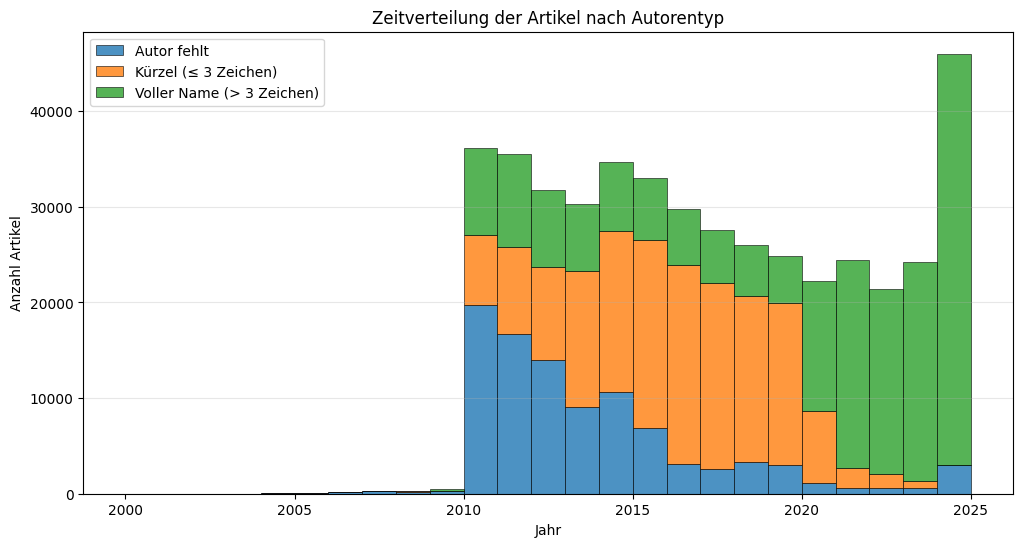

In [12]:
# Plot: Zeitverteilung der Artikel nach Autoren-Kategorie
data["datum"] = pd.to_datetime(data["datum"])
data["jahr"] = data["datum"].dt.year
data["monat"] = data["datum"].dt.month
data["tag"] = data["datum"].dt.day

# Kategorien definieren
mask_missing = data["autor"].isna()
mask_short = (~mask_missing) & (data["autor"].str.len() <= 3)
mask_long = (~mask_missing) & (data["autor"].str.len() > 3)

plt.figure(figsize=(12, 6))
plt.hist(
    [data[mask_missing]["jahr"], data[mask_short]["jahr"], data[mask_long]["jahr"]],
    bins=range(2000, 2026),
    stacked=True,
    label=["Autor fehlt", "Kürzel (≤ 3 Zeichen)", "Voller Name (> 3 Zeichen)"],
    edgecolor="black",
    linewidth=0.5,
    alpha=0.8,
)

plt.xlabel("Jahr")
plt.ylabel("Anzahl Artikel")
plt.title("Zeitverteilung der Artikel nach Autorentyp")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

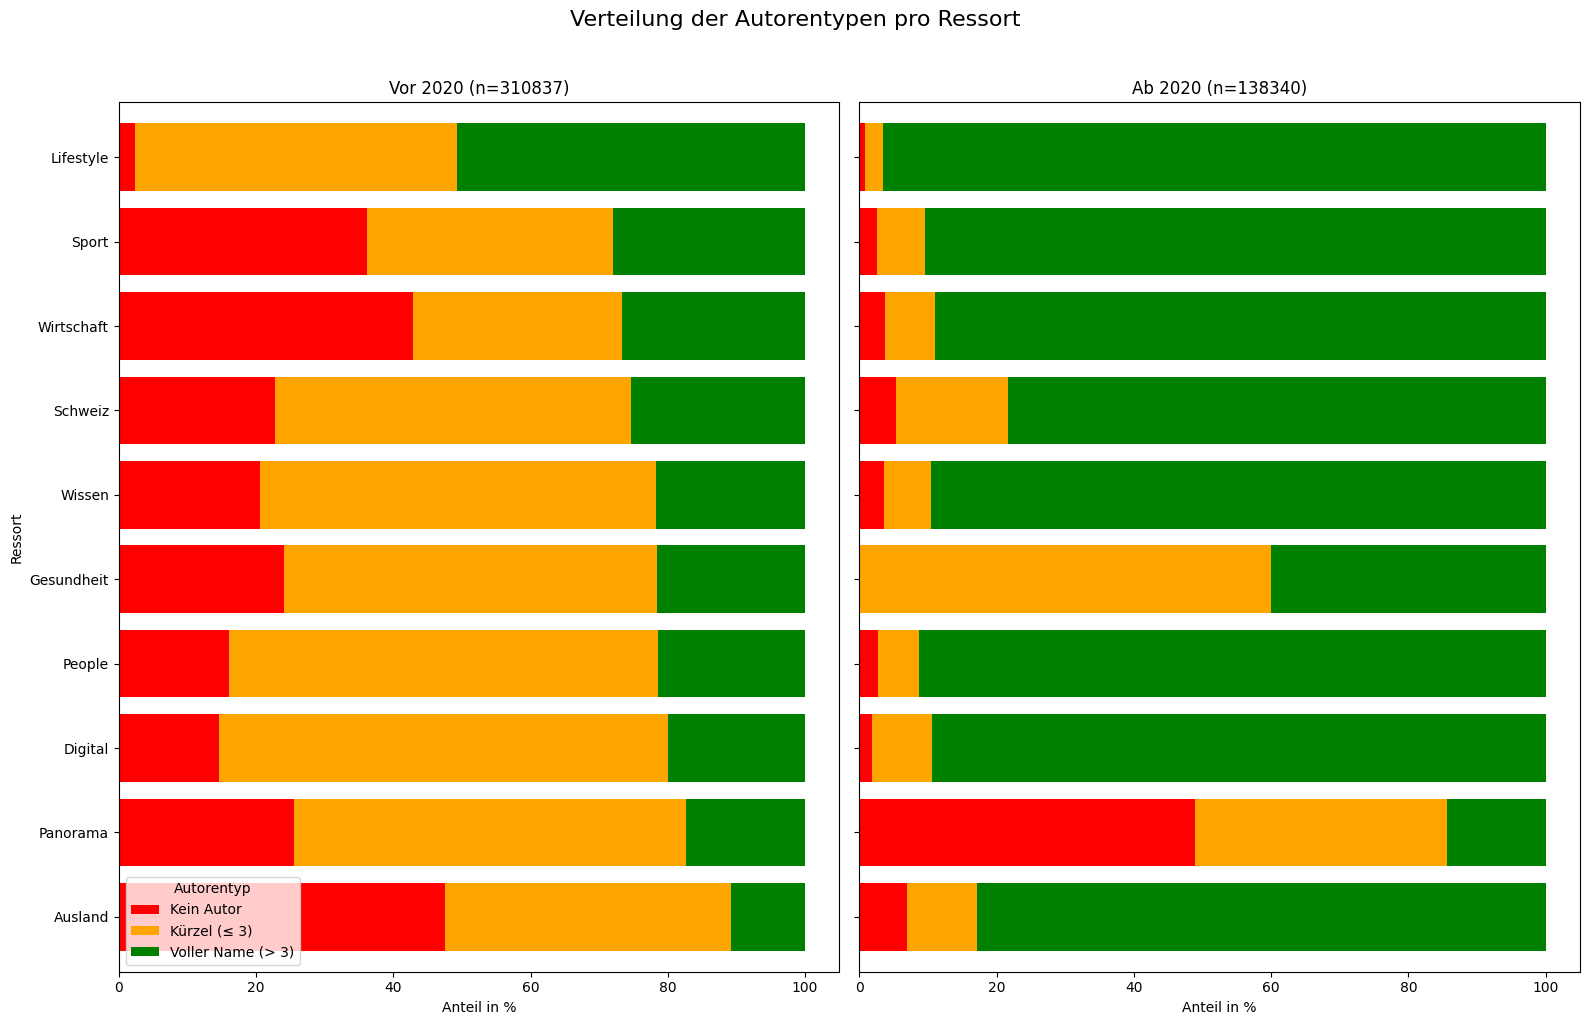

In [13]:
# Verteilung von Artikeln mit kein Autor, Kürzel (≤ 3 Zeichen) und voller Name (> 3 Zeichen) nach resort in Prozent

# 1. Autorentyp bestimmen (basierend auf den Masken der vorherigen Zelle)
data["author_type"] = "Kein Autor"
data.loc[mask_short, "author_type"] = "Kürzel (≤ 3)"
data.loc[mask_long, "author_type"] = "Voller Name (> 3)"

# 2. Daten splittern
df_pre_2020 = data[data["datum"].dt.year < 2020]
df_post_2020 = data[data["datum"].dt.year >= 2020]


# 3. Prozentverteilung pro Ressort berechnen
def calculate_ressort_percentages(df):
    # Kreuztabelle: Zeilen=Ressort, Spalten=Autorentyp
    ct = pd.crosstab(df["ressort"], df["author_type"])
    # Normalisieren auf 100% pro Zeile
    return ct.div(ct.sum(axis=1), axis=0) * 100


pct_pre = calculate_ressort_percentages(df_pre_2020)
pct_post = calculate_ressort_percentages(df_post_2020)

# Optional: Filtern von Ressorts mit sehr wenigen Artikeln, damit die Grafik sauber bleibt
min_articles = 50
ressorts_pre = df_pre_2020["ressort"].value_counts()
ressorts_post = df_post_2020["ressort"].value_counts()
valid_ressorts = ressorts_pre[ressorts_pre > min_articles].index.intersection(
    ressorts_post[ressorts_post > min_articles].index
)

pct_pre = pct_pre.loc[valid_ressorts]
pct_post = pct_post.loc[valid_ressorts]

# Sortierung für bessere Lesbarkeit (z.B. nach Anteil "Voller Name")
if "Voller Name (> 3)" in pct_pre.columns:
    sort_order = pct_pre["Voller Name (> 3)"].sort_values().index
    pct_pre = pct_pre.loc[sort_order]
    pct_post = pct_post.reindex(sort_order)

# 4. Plotten
fig, axes = plt.subplots(1, 2, figsize=(16, 10), sharey=True)

# Farbschema festlegen für Konsistenz
colors = {"Kein Autor": "red", "Kürzel (≤ 3)": "orange", "Voller Name (> 3)": "green"}
color_list = [colors.get(c, "gray") for c in pct_pre.columns]

pct_pre.plot(kind="barh", stacked=True, ax=axes[0], color=color_list, width=0.8)
axes[0].set_title(f"Vor 2020 (n={len(df_pre_2020)})")
axes[0].set_xlabel("Anteil in %")
axes[0].set_ylabel("Ressort")
axes[0].legend(title="Autorentyp", loc="lower left")

pct_post.plot(kind="barh", stacked=True, ax=axes[1], color=color_list, width=0.8)
axes[1].set_title(f"Ab 2020 (n={len(df_post_2020)})")
axes[1].set_xlabel("Anteil in %")
axes[1].legend().remove()  # Legende nur einmal nötig

plt.suptitle("Verteilung der Autorentypen pro Ressort", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

# Entfernen von Authorentyp Spalte, da sie nur für die Analyse relevant war
data.drop(columns=["author_type"], inplace=True)

In [14]:
# Summe von Artikeln mit Autor und Autor-länge > 3
sum_long = mask_long.sum()
print(f"Anzahl Artikel mit Autor und Autor-Länge > 3: {sum_long}")

Anzahl Artikel mit Autor und Autor-Länge > 3: 189711


### Nach ```likes```

In [15]:
# Artikel die likes = NaN haben
data[data["likes"].isna()]

,id,url,datum,titel,beschreibung,autor,quelle,ressort,likes,kommentare,kommentare_erlaubt,shares,keywords,clean_terms,jahr,monat,tag
232857,232858,https://www.20min.ch/story/so-trinken-sie-alko...,2017-01-05 11:45:00+00:00,So trinkst du Alkohol richtig,Prost miteinander: Alkohol gehört für viele Me...,NaN,20 Minuten,Panorama,NaN,NaN,False,NaN,"Fantasy (0.0174), League (0.0174), Radio (0.01...","Lifestyle, Fantasy, League, Wetter, Radio, Pap...",2017,1,5
301010,301011,https://www.20min.ch/story/rihanna-rechnet-mit...,2019-08-06 10:03:52+00:00,Rihanna rechnet mit Donald Trump ab,Nach den Massenschiessereien am Wochenende kri...,Gloria Karthan,20 Minuten,Rihanna rechnet mit Donald Trump ab,NaN,NaN,False,NaN,"Rihanna (0.0521), Promis (0.0705), Wochenende ...","Rihanna, the, Terrorismus, Donald, Trumps, Tru...",2019,8,6
307584,307585,https://www.20min.ch/story/aargauer-sektenguru...,2019-11-11 11:08:10.907000+00:00,Aargauer Sektenguru muss neun Jahre ins Gefängnis,Wegen mehrfacher sexueller Nötigung stand ein ...,SDA,20 Minuten,Schweiz,NaN,NaN,False,NaN,"Aargauer (0.0394), Bundesgericht (0.0529), Nöt...","Bundesgericht, Mann, Frauen, Obergerichts, Obe...",2019,11,11
307590,307591,https://www.20min.ch/story/adidas-verlagert-sc...,2019-11-11 09:43:07.586000+00:00,Adidas verlagert Schuhproduktion nach Asien,Der Sportriese verlagert die erst vor wenigen ...,Barbara Lanz,20 Minuten,Wirtschaft,NaN,NaN,False,NaN,"Asien (0.0590), Sportriese (0.0778), Produktio...","Asien, Adidas, Schuhproduktion, Deutschland, T...",2019,11,11
307893,307894,https://www.20min.ch/story/eisbaerin-hertha-sp...,2019-11-15 13:45:23.407000+00:00,Eisbärin Hertha spielt Ball,Im Berliner Tierpark ist der Bär los.,NaN,20 Minuten,Panorama,NaN,NaN,False,NaN,"Fantasy (0.0174), League (0.0174), Radio (0.01...","Lifestyle, Fantasy, League, Wetter, Radio, Pap...",2019,11,15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
415632,415633,https://www.20min.ch/story/celebrity-verhaftun...,2024-06-22 16:57:53.211000+00:00,Justin Timberlake und Justin Bieber: Virale Pr...,Sänger Justin Timberlake wurde jüngst wegen Tr...,NaN,20 Minuten,People,NaN,NaN,False,NaN,"Fantasy (0.0174), League (0.0174), Radio (0.01...","Lifestyle, Fantasy, League, Wetter, Radio, Pap...",2024,6,22
417371,417372,https://www.20min.ch/story/olympia-2024-die-gr...,2024-07-17 08:47:16.357000+00:00,Olympia 2024: Das sind die grössten Stars der ...,Olympia steht vor der Tür. Das sind die grösst...,NaN,20 Minuten,Olympia 2024: Das sind die grössten Stars der ...,NaN,NaN,True,NaN,"Fantasy (0.0174), League (0.0174), Radio (0.01...","Lifestyle, Fantasy, League, Wetter, Radio, Pap...",2024,7,17
419138,419139,https://www.20min.ch/story/paris-2024-oh-la-la...,2024-08-12 07:35:21.988000+00:00,"Oh, là, là an Olympia – Diese Topshots rauben ...",Die spektakulärsten Bilder von Olympia,NaN,20 Minuten,"Oh, là, là an Olympia – Diese Topshots rauben ...",NaN,NaN,False,NaN,"Fantasy (0.0174), League (0.0174), Radio (0.01...","Lifestyle, Fantasy, League, Wetter, Radio, Pap...",2024,8,12
427012,427013,https://www.20min.ch/story/mariah-carie-john-o...,2024-11-30 16:35:30.240000+00:00,"Mariah Carie, John Oates und Co.: So viele Sex...","Charlie Sheen, Mariah Carie, Russell Brand und...",NaN,20 Minuten,People,NaN,NaN,False,NaN,"Fantasy (0.0174), League (0.0174), Radio (0.01...","Lifestyle, Fantasy, League, Wetter, Radio, Pap...",2024,11,30


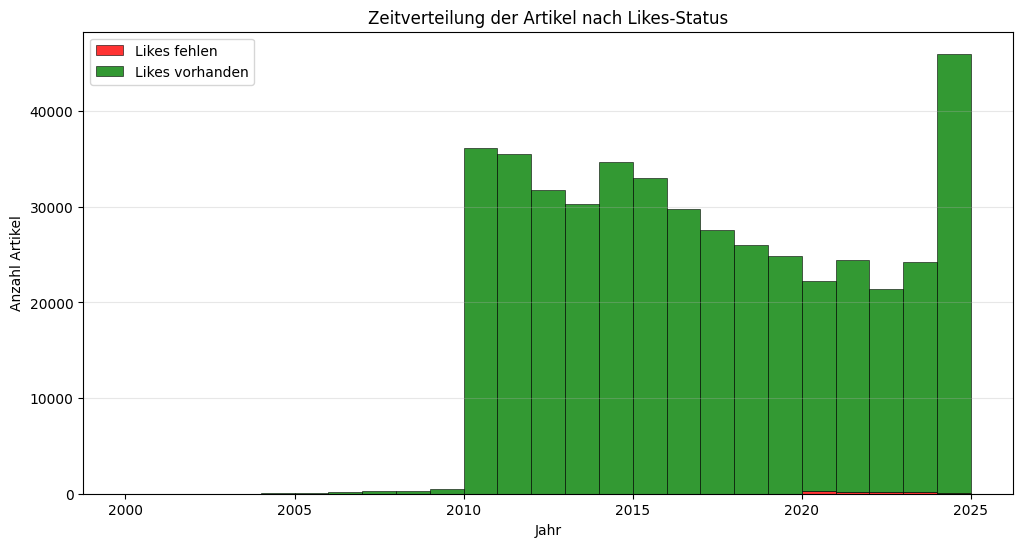

In [16]:
# Plot: Zeitverteilung der Artikel nach Likes-Status (Vorhanden vs. Fehlend)

# Kategorien definieren
mask_likes_missing = data["likes"].isna()
mask_likes_present = ~mask_likes_missing

plt.figure(figsize=(12, 6))
plt.hist(
    [data[mask_likes_missing]["jahr"], data[mask_likes_present]["jahr"]],
    bins=range(2000, 2026),
    stacked=True,
    label=["Likes fehlen", "Likes vorhanden"],
    edgecolor="black",
    linewidth=0.5,
    alpha=0.8,
    color=["red", "green"],
)

plt.xlabel("Jahr")
plt.ylabel("Anzahl Artikel")
plt.title("Zeitverteilung der Artikel nach Likes-Status")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

In [17]:
# Von allen Artikeln ohne Likes soll nach keywords gruppiert werden, um zu sehen, ob es bestimmte Themen gibt, die häufiger keine Likes haben

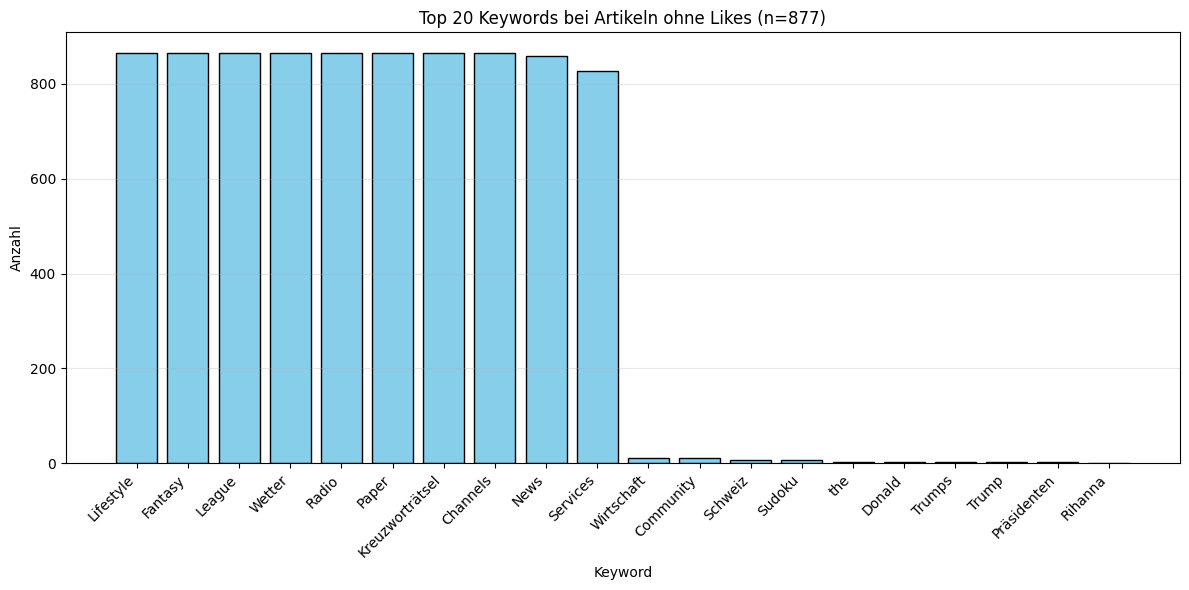

,Keyword,Anzahl
0,Lifestyle,865
1,Fantasy,865
2,League,865
3,Wetter,865
4,Radio,865
5,Paper,865
6,Kreuzworträtsel,865
7,Channels,865
8,News,859
9,Services,826


In [18]:
# Häufigste Keywords bei Artikeln ohne Likes

from collections import Counter

# Artikel ohne Likes filtern
df_no_likes = data[mask_likes_missing].copy()

# Counter für Keywords initialisieren
keyword_counts = Counter()

# Keywords extrahieren und zählen (nutzt 'clean_terms' wenn vorhanden, sonst fallback oder string parsing)
# Die Spalte 'clean_terms' enthält kommagetrennte Strings.
# Wenn 'clean_terms' NaN ist, ignorieren wir die Zeile.
clean_terms_series = df_no_likes["clean_terms"].dropna()

for terms in clean_terms_series:
    if isinstance(terms, str):
        # Split am Komma und Whitespace entfernen
        split_keywords = [k.strip() for k in terms.split(",")]
        keyword_counts.update(split_keywords)

# Top 20 Keywords
most_common_df = pd.DataFrame(
    keyword_counts.most_common(20), columns=["Keyword", "Anzahl"]
)

# Plotten
plt.figure(figsize=(12, 6))
plt.bar(
    most_common_df["Keyword"],
    most_common_df["Anzahl"],
    color="skyblue",
    edgecolor="black",
)
plt.xlabel("Keyword")
plt.ylabel("Anzahl")
plt.title(f"Top 20 Keywords bei Artikeln ohne Likes (n={len(df_no_likes)})")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

most_common_df

### Nach ```kommentare```

In [19]:
# Alle unique Kombinationen von der kommentare_erlaubt
data[data["kommentare_erlaubt"] == False]

,id,url,datum,titel,beschreibung,autor,quelle,ressort,likes,kommentare,kommentare_erlaubt,shares,keywords,clean_terms,jahr,monat,tag
0,1,https://www.20min.ch/story/robert-palmer-ist-t...,2003-10-01 13:40:00+00:00,Nachruf: Robert Palmer ist tot,Der britische Popmusiker Robert Palmer ist tot...,Jonas Bucher,20 Minuten,People,0.0,NaN,False,0.0,"Palmer (0.0339), Robert (0.0582), tot (0.0630)...","Palmer, Robert, Paris, Angaben, Staatsanwaltsc...",2003,10,1
1,2,https://www.20min.ch/story/ohne-grenzgaenger-g...,2003-10-01 02:42:00+00:00,Eric Weber: «Ohne Grenzgänger gäbe es keine Ar...,Ständeratskandidat Eric Weber von der Volks-Ak...,Daniel Waldmeier,20 Minuten,Schweiz,4.0,NaN,False,0.0,"Weber (0.0358), Ständeratskandidat (0.0670), A...","Weber, Eric, Grenzgänger, Schweiz, Basel, Arbe...",2003,10,1
2,3,https://www.20min.ch/story/der-drache-hat-ausg...,2003-10-20 02:06:00+00:00,Drachenboot Thunersee: Der Drache hat ausgefaucht,Abschiedsfahrt des Drachenschiffs.,Jonas Bucher,20 Minuten,Schweiz,11.0,NaN,False,0.0,"Thunersee (0.0723), Drachenboot (0.0756), Drac...","Thunersee, Fauchi, Abschiedsfahrt, Drachenschi...",2003,10,20
3,4,https://www.20min.ch/story/bohlen-und-jeanette...,2003-10-01 12:26:00+00:00,Dieter Bohlen: «Jeanettes Popo war wie zwei Su...,Bohlen und Jeanettes Popo,Jonas Bucher,20 Minuten,People,5.0,NaN,False,0.0,"Bohlen (0.0578), Dieter (0.0661), Titan (0.075...","Jeanette, Bohlen, Popo, Dieter, Naddel, Sarah,...",2003,10,1
4,5,https://www.20min.ch/story/hitlers-letzter-adj...,2003-10-01 10:30:00+00:00,Otto Günsche: Hitlers letzter Adjutant ist tot,Hitlers letzter Adjutant Otto Günsche ist im A...,Jonas Bucher,20 Minuten,Wissen,0.0,NaN,False,0.0,"Günsche (0.0255), Hitlers (0.0357), letzter (0...","Günsche, Hitlers, Reichskanzlei, Adjutant, Ott...",2003,10,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
449161,449162,https://www.20min.ch/story/umfrage-eigenmietwe...,2025-09-25 02:32:41.151000+00:00,Deine Stimme zählt – Mach mit bei der Umfrage ...,Am 28. September entscheidet die Schweiz. Sag ...,Jean-Claude Gerber,20 Minuten,Schweiz,2483.0,NaN,False,121.0,"Eigenmietwert (0.0627), Minuten (0.0878), Umfr...","Whatsapp, Storys, Sag, Eigenmietwertbesteuerun...",2025,9,25
449168,449169,https://www.20min.ch/story/george-clooney-co-1...,2025-09-25 02:32:09.600000+00:00,1500 Autogramme: Michael sammelt Unterschrifte...,Seit 2013 reist Michael aus Österreich zu Film...,Leonie Projer,20 Minuten,People,136.0,NaN,False,11.0,"Michael (0.0234), Welt (0.0273), Film (0.0382)...","Michael, Autogramme, Autogramm, Stars, Film, Z...",2025,9,25
449169,449170,https://www.20min.ch/story/rekordzahlen-millio...,2025-09-25 00:30:56.649000+00:00,Millionen verfolgten Kimmels Comeback,Die auf Druck der US-Regierung kurzzeitig abge...,Daniela Wyler; Deutsche Presse-Agentur,20 Minuten,Ausland,112.0,NaN,False,1.0,"Millionen (0.0192), Zuschauer (0.0389), Kimmel...","Millionen, Zuschauer, Kimmel, ABC, Kimmels, Ji...",2025,9,25
449170,449171,https://www.20min.ch/story/wiederholungstaeter...,2025-09-25 02:30:24.919000+00:00,«Wir fühlen uns ohnmächtig»: Frauen in Vilters...,Ein 27-Jähriger zeigt sich mehrfach vor Frauen...,Matilda Hänggi; Daniel Graf; Carolin Teufelber...,20 Minuten,Schweiz,2542.0,NaN,False,852.0,"Frauen (0.0148), Polizei (0.0303), Vilters (0....","Frauen, Mann, Polizei, Vilters, Wegweisung, Mo...",2025,9,25


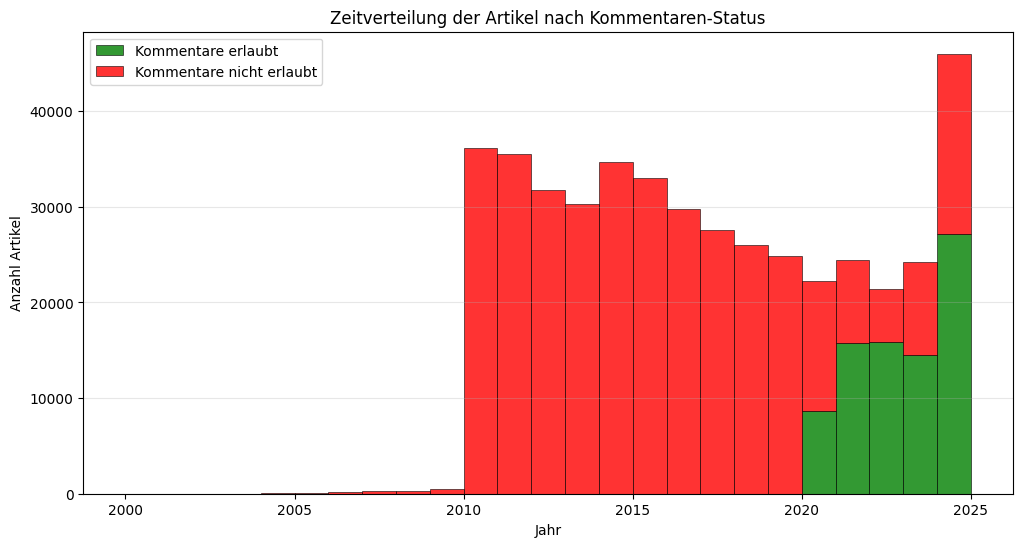

In [20]:
# Plot: Zeitverteilung der Artikel nach kommentare_erlaubt-Status (Vorhanden vs. Fehlend)
# Kategorien definieren
mask_comments_allowed = data["kommentare_erlaubt"] == True
mask_comments_not_allowed = ~mask_comments_allowed
plt.figure(figsize=(12, 6))
plt.hist(
    [data[mask_comments_allowed]["jahr"], data[mask_comments_not_allowed]["jahr"]],
    bins=range(2000, 2026),
    stacked=True,
    label=["Kommentare erlaubt", "Kommentare nicht erlaubt"],
    edgecolor="black",
    linewidth=0.5,
    alpha=0.8,
    color=["green", "red"],
)
plt.xlabel("Jahr")
plt.ylabel("Anzahl Artikel")
plt.title("Zeitverteilung der Artikel nach Kommentaren-Status")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

### Fazit
- Artikel
  - Die Artikel ohne Beschreibung sind mehrheitlich Artikel die nur Bilder beinhalten. Diese können entfernt werden. Der Artikel mit der ```id``` = 356461 ist ein nicht vollständiger Artikel. 
- Autoren
  - Missing Autoren und Autoren mit Kürzel haben von Jahr zu Jahr abgenommen. 
  - Ab dem Jahr 2020 haben die Autoren mit vollen Namen zugenommen. 
    - Nach weiterer Analyse ist ersichtlich, dass dies jedoch nur in bestimmten ```resorts``` der Fall ist. 
- Likes
  - Wir sehen eine Zunahme von Artikeln ohne Likes in dem jahr 2020. Jedoch machen die Artikel ohne Likes einen Bruchteil aus.
  - Die ```keywords``` Lifestyle, Fantasy, League, Wetter, Radio, Paper, Kreutsworträtsel, Channels, News und Services haben am meisten die Likes deaktiviert. 
- Kommentare
  - Ab dem Jahr 2020 wurden Kommentare aktiviert für einige Artikel. Im Schnitt sind die kommentare aktiviert für 50-70% der Artikel nach dem Jahr 2020. 


>Alle Artikel mit fehlender Beschreibung werden entfernt
>Alle Artikel mit Autor Kürzel und fehlenden Autoren werden auch entfernt. Diese entscheidung treffen wir, da der Datensatz enrom gross ist. So arbeiten wir mit sauberen Daten und weniger Daten, was die Analyse effizienter gestaltet.
> Alle Artikel vor dem Jahr 2020 werden entfernt um den Datensatz ersichtlicher zu behalten.  

In [21]:
# Entfernen von den Zeilen mit fehlenden autor Werten und Autoren mit Kürzel (≤ 3 Zeichen)
data = data[mask_long]  # Behält nur Zeilen mit vollem Namen (> 3 Zeichen)

In [22]:
# Entfernen von den Zeilen mit fehlenden beschreibung Werten
data = data.dropna(subset=["beschreibung"])

In [23]:
# Entfernen von Artikeln vor dem Jahr 2020
data = data[data["datum"].dt.year >= 2020]

## Duplikate

In [24]:
# Identifizieren und Zählen von Duplikaten in Object-Spalten

# 1. Alle Spalten vom Typ 'object' (String) finden
obj_cols = data.select_dtypes(include=["object"]).columns

# 2. Summe der Duplikate pro Spalte anzeigen
print("Anzahl der Duplikate pro Spalte (Typ: Object):")
print("-" * 40)
for col in obj_cols:
    # `duplicated()` gibt True zurück, wenn der Wert schon mal vorkam.
    # `.sum()` zählt alle True-Werte (= Anzahl der Duplikate nach dem ersten Vorkommen)
    num_duplicates = data[col].duplicated().sum()
    print(f"{col}: {num_duplicates}")

Anzahl der Duplikate pro Spalte (Typ: Object):
----------------------------------------
url: 0
titel: 111
beschreibung: 175
autor: 114792
quelle: 120494
ressort: 117992
keywords: 29
clean_terms: 56


In [25]:
# Alle Zeilen mit Duplikaten in der 'titel' Spalte anzeigen
duplicate_titles = data[data["titel"].duplicated(keep="first")]
print(f"\nAnzahl der Zeilen mit duplizierten Titeln: {len(duplicate_titles)}")
duplicate_titles[["id", "url", "titel", "beschreibung", "datum"]]


Anzahl der Zeilen mit duplizierten Titeln: 111


,id,url,titel,beschreibung,datum
313730,313731,https://www.20min.ch/story/aergert-tuchel-sein...,Haaland zeigt Neymar und PSG den Meister,Das BVB-Wunderkind trifft gegen Paris doppelt....,2020-02-18 19:49:42.213000+00:00
313790,313791,https://www.20min.ch/story/kann-leipzig-auswae...,Leipzig siegt auswärts – Freuler trifft für At...,RB Leipzig gewinnt das Achtelfinal-Hinspiel ge...,2020-02-19 19:38:29.439000+00:00
313861,313862,https://www.20min.ch/story/findet-basel-in-der...,Basel machts mit links und holt Schwung,Ein selbstbewusster FCB gewinnt gegen Apoel Ni...,2020-02-20 19:31:32.626000+00:00
314155,314156,https://www.20min.ch/story/schiesst-sich-lewan...,"Bayern-Gala in London, Barça muss beissen",3:0 besiegt Bayern München Chelsea. Für die Mü...,2020-02-25 19:41:31.269000+00:00
314854,314855,https://www.20min.ch/story/die-letzte-abfahrt-...,Ausgerechnet Janka stösst Feuz vom Podest,In Kvitfjell schafft Carlo Janka als Dritter d...,2020-03-07 09:46:00+00:00
...,...,...,...,...,...
441455,441456,https://www.20min.ch/story/lehrer-sind-dafuer-...,8 Wochen Ferien für Lernende? Forderung sorgt ...,Schweizer Lernende fordern 8 Wochen Ferien. Ge...,2025-06-13 02:52:32.731000+00:00
443014,443015,https://www.20min.ch/story/euro-2025-haessige-...,«Stinker-Raclette kostet 20 Franken»: Deutsche...,«Bild»-Reporter über Fanzone Zürich: 20 Franke...,2025-07-05 09:47:26.015000+00:00
443678,443679,https://www.20min.ch/story/wetter-regenschirm-...,Schweiz: So wird das Wetter diese Woche,Der Start in die neue Woche bringt verbreitet ...,2025-07-14 04:31:35.003000+00:00
447119,447120,https://www.20min.ch/story/taylor-swift-und-tr...,Taylor Swift und Travis Kelce: Vater des NFL-S...,Taylor Swift und Travis Kelce sind seit zwei W...,2025-08-29 14:10:24.608000+00:00


### Fazit
- Nach genauerer Analyse scheint es so, dass die Duplikate ein Fehler von der 20min ist und nicht von dem Scraping tool. 

## Plausibilität

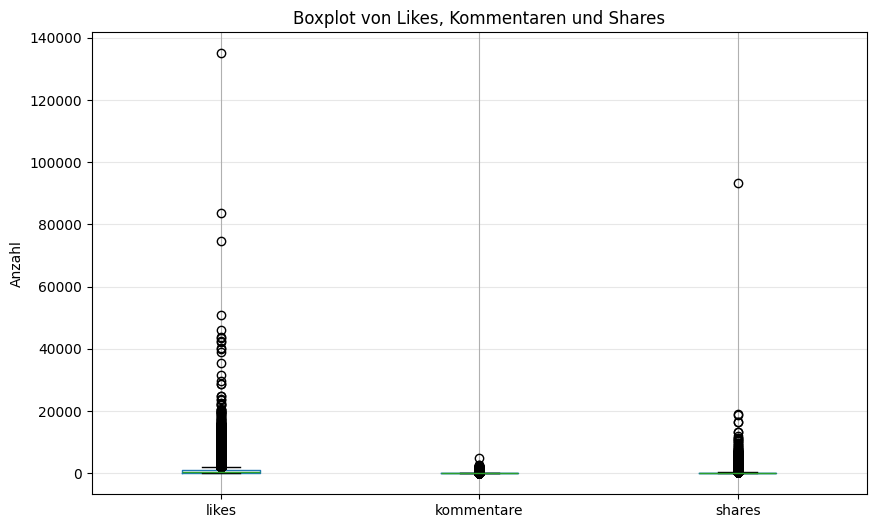

In [26]:
# Boxplot von likes, kommentare und shares
plt.figure(figsize=(10, 6))
data[["likes", "kommentare", "shares"]].boxplot()
plt.title("Boxplot von Likes, Kommentaren und Shares")
plt.ylabel("Anzahl")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [27]:
# Ausgabe von dem Artikeln mit den meisten Likes
top_likes = data.sort_values(by="likes", ascending=False).head(10)
top_likes[["id", "url", "titel", "beschreibung", "likes"]]

,id,url,titel,beschreibung,likes
328649,328650,https://www.20min.ch/story/corona-zahlen-schwe...,«Wir wollen eine dritte Welle verhindern»,Nachdem Alain Berset gestern eindringlich davo...,135031.0
446933,446934,https://www.20min.ch/story/wetter-schweiz-am-s...,Regenschirm dabei? Bund warnt vor erheblichem ...,"Ob Hitzetag, Regen und Gewitter oder Schnee, i...",83525.0
354280,354281,https://www.20min.ch/story/polizeimeldungen-re...,Füllinsdorf BL – Betrunkener kracht mit BMW in...,Ein 41-jähriger BMW-Lenker verursachte in Füll...,74701.0
448993,448994,https://www.20min.ch/story/karim-benzema-mouri...,Manchester United auf der Suche nach neuem Tra...,Die Situation bei Manchester United spitzt sic...,50970.0
329548,329549,https://www.20min.ch/story/ersten-resultate-ko...,Joe Biden gewinnt US-Wahl mit 306 Wahlleuten,Der Demokrat Joe Biden hat bei der US-Wahl nac...,45949.0
352189,352190,https://www.20min.ch/story/myokarditis-studie-...,"Corona-Faktencheck – Nein, der Biontech/Pfizer...",Echt oder fake? Diese Frage stellt man sich an...,43920.0
328189,328190,https://www.20min.ch/story/corona-zahlen-schwe...,Glarus verschärft die Massnahmen – Skigebiete ...,Im Kanton Genf werden die Restaurants und Bars...,43518.0
449061,449062,https://www.20min.ch/story/europa-league-dank-...,Real Madrid und Liverpool: Erste Saisonpleiten...,Liverpool verliert überraschend gegen Crystal ...,42485.0
329459,329460,https://www.20min.ch/story/donald-trump-gegen-...,Trump leitet Prozess zur Amtsübergabe an Biden...,Joe Biden wird der 46. Präsident der USA. Mit ...,42152.0
323488,323489,https://www.20min.ch/story/die-schweiz-schwitz...,Sommer meldet sich ab Freitag zurück,Nach heftigen Gewittern und Regenfällen steige...,40124.0


In [28]:
# Ausgabe von dem Artikeln mit den meisten Kommentaren
top_comments = data.sort_values(by="kommentare", ascending=False).head(10)
top_comments[["id", "url", "titel", "beschreibung", "kommentare"]]

,id,url,titel,beschreibung,kommentare
448229,448230,https://www.20min.ch/story/bundesbern-ticker-s...,150 Millionen für gemeinnützige Wohnungen: Bun...,"Der Bundesrat hat am Freitag entschieden, 150 ...",5011.0
449034,449035,https://www.20min.ch/story/regio-ticker-zueric...,Kunsthaus Zürich wird cashless: Digitale Zahlu...,Seit dem 1. September akzeptiert das Kunsthaus...,2807.0
334018,334019,https://www.20min.ch/story/skigebiete-freuen-s...,Riesenansturm auf Skigebiete – Flumserberg ste...,Die Skigebiete rechneten für Samstag mit einem...,2770.0
324375,324376,https://www.20min.ch/story/eine-schweiz-mit-10...,«Eine Schweiz mit 10 Millionen Einwohnern ist ...,In der «Abstimmungsarena» wurde wieder einmal ...,2449.0
354349,354350,https://www.20min.ch/story/die-corona-zahlen-k...,«Die Corona-Zahlen könnten in drei Wochen alle...,"Die Fallzahlen steigen stark an, die Impfquote...",2311.0
324308,324309,https://www.20min.ch/story/das-sagen-betroffen...,Das sagen Betroffene zur Maskenpflicht in Base...,Ab Montag müssen in Basel nicht mehr nur im ÖV...,2309.0
355968,355969,https://www.20min.ch/story/braucht-es-schon-di...,"2G, Massentests, Impfpflicht – Braucht es scho...",Die Situation in den Spitälern spitzt sich wei...,2246.0
326411,326412,https://www.20min.ch/story/stecke-meine-sieben...,«Stecke meine siebenjährige Tochter nicht in C...,F. M. müsste seine siebenjährige Tochter zehn ...,2198.0
350562,350563,https://www.20min.ch/story/ab-montag-gehe-ich-...,Ausgedehntes Covid-Zertifikat - «Ab Montag geh...,"Verzicht auf das Lieblingscafé, den Verband od...",2073.0
328120,328121,https://www.20min.ch/story/eine-strukturierte-...,«Eine strukturierte Durchseuchung wäre der ric...,Der Ökonom Reiner Eichenberger will die Schwei...,2020.0


In [29]:
# Ausgabe von dem Artikeln mit den meisten Shares
top_shares = data.sort_values(by="shares", ascending=False).head(10)
top_shares[["id", "url", "titel", "beschreibung", "shares"]]

,id,url,titel,beschreibung,shares
446933,446934,https://www.20min.ch/story/wetter-schweiz-am-s...,Regenschirm dabei? Bund warnt vor erheblichem ...,"Ob Hitzetag, Regen und Gewitter oder Schnee, i...",93485.0
354280,354281,https://www.20min.ch/story/polizeimeldungen-re...,Füllinsdorf BL – Betrunkener kracht mit BMW in...,Ein 41-jähriger BMW-Lenker verursachte in Füll...,19025.0
445222,445223,https://www.20min.ch/story/stau-vor-dem-gottha...,Axenstrasse nach Steinschlag wiederoffen,Gumpisch: Die Axenstrasse ist nach Steinschlag...,18814.0
432919,432920,https://www.20min.ch/story/medikament-rueckruf...,Rückruf: Vitamin D3 Streuli wegen Glassplitter...,Wegen eines Qualitätsmangels kann es in gewiss...,16640.0
448229,448230,https://www.20min.ch/story/bundesbern-ticker-s...,150 Millionen für gemeinnützige Wohnungen: Bun...,"Der Bundesrat hat am Freitag entschieden, 150 ...",16426.0
328084,328085,https://www.20min.ch/story/das-bedeutet-die-de...,Wer darf jetzt noch nach Deutschland reisen?,Deutschland erklärt die ganze Schweiz zum Risi...,13309.0
439928,439929,https://www.20min.ch/story/facebook-und-instag...,"Meta AI: So verhinderst du, dass deine Daten v...",Ab dem 27. Mai nutzt Meta öffentliche Facebook...,13190.0
417612,417613,https://www.20min.ch/story/weltweiter-it-ausfa...,"Weltweite IT-Panne: 8,5 Millionen Computer bet...",Weltweit sind Computersysteme gestört. Auch di...,12082.0
419089,419090,https://www.20min.ch/story/leissigen-be-ein-so...,Unwetter Berner Oberland: Verletzte und mehrer...,Heftige Gewitter haben Brienz heimgesucht und ...,11339.0
448993,448994,https://www.20min.ch/story/karim-benzema-mouri...,Manchester United auf der Suche nach neuem Tra...,Die Situation bei Manchester United spitzt sic...,11220.0


### Fazit
- Bei de Artikeln mit hohen Kommentaren ist klar ersichtlich, dass Covid immer ein grosses thema ist. 
- Bei likes und shares sind die Themen sehr vielfälltig. 

# Übersicht nach dem Cleaning

In [30]:
print(f"Nach dem Cleaning haben wir {len(data)} Artikel in unserem Datensatz.")

Nach dem Cleaning haben wir 120495 Artikel in unserem Datensatz.


In [31]:
data.columns

Index(['id', 'url', 'datum', 'titel', 'beschreibung', 'autor', 'quelle',
       'ressort', 'likes', 'kommentare', 'kommentare_erlaubt', 'shares',
       'keywords', 'clean_terms', 'jahr', 'monat', 'tag'],
      dtype='object')